In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
pd.options.display.max_columns = None

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:
%cd /content/drive/MyDrive/Machine\ Learning

/content/drive/MyDrive/Machine Learning


In [ ]:
!ls

bigFlows.csv  bottom.csv	dataset.csv	  vpn_vnat_binary.csv
botnet.csv    clustering.ipynb	samplingFile.csv


In [ ]:
flow_filtered = pd.read_csv("dataset.csv")
flow_filtered.head()

,timestamp,datapath_id,flow_id,ip_src,tp_src,ip_dst,tp_dst,ip_proto,icmp_code,icmp_type,flow_duration_sec,flow_duration_nsec,idle_timeout,hard_timeout,flags,packet_count,byte_count,packet_count_per_second,packet_count_per_nsecond,byte_count_per_second,byte_count_per_nsecond,label
0,1.589933e+09,1,10.0.0.1505010.0.0.3542466,10.0.0.1,5050,10.0.0.3,54246,6,-1,-1,4,480000000,20,100,0,50776,3351216,12694.00,1.057833e-04,8.378040e+05,6.981700e-03,0
1,1.589933e+09,1,10.0.0.35424610.0.0.150506,10.0.0.3,54246,10.0.0.1,5050,6,-1,-1,4,486000000,20,100,0,209360,11834974848,52340.00,4.307819e-04,2.958744e+09,2.435180e+01,0
2,1.589933e+09,1,10.0.0.35424610.0.0.550501,10.0.0.3,54246,10.0.0.5,5050,1,0,8,4,484000000,20,100,0,3,294,0.75,6.198347e-09,7.350000e+01,6.074380e-07,0
3,1.589933e+09,1,10.0.0.55424610.0.0.350501,10.0.0.5,54246,10.0.0.3,5050,1,0,0,4,415000000,20,100,0,3,294,0.75,7.228916e-09,7.350000e+01,7.084337e-07,0
4,1.589933e+09,2,10.0.0.3010.0.0.501,10.0.0.3,0,10.0.0.5,0,1,0,8,4,423000000,20,100,0,3,294,0.75,7.092199e-09,7.350000e+01,6.950355e-07,0


In [ ]:
# sns.lineplot(x=flow_filtered["timestamp"], y=flow_filtered['flow_duration_sec'])

# plt.show()

In [ ]:
flow = flow_filtered[["timestamp", "flow_duration_sec"]]

In [ ]:
flow.head()

,timestamp,flow_duration_sec
0,2020-05-19 23:59:06.261578083,4
1,2020-05-19 23:59:06.261578083,4
2,2020-05-19 23:59:06.261578083,4
3,2020-05-19 23:59:06.261578083,4
4,2020-05-19 23:59:06.262135029,4


In [ ]:
flow.shape

(2667523, 2)

In [ ]:
flow.duplicated().sum()

np.int64(2253857)

In [ ]:
flow = flow.copy()
flow.drop_duplicates(inplace=True)

In [ ]:
flow.duplicated().sum()

np.int64(0)

In [ ]:
flow.reset_index(drop=True, inplace=True)

In [ ]:
flow.head()

,timestamp,flow_duration_sec
0,2020-05-19 23:59:06.261578083,4
1,2020-05-19 23:59:06.262135029,4
2,2020-05-19 23:59:16.274843931,14
3,2020-05-19 23:59:16.281681061,14
4,2020-05-19 23:59:16.281681061,4


In [ ]:
flow.shape

(413666, 2)

In [ ]:
flow["timestamp"].iloc[:300]

,timestamp
0,2020-05-19 23:59:06.261578083
1,2020-05-19 23:59:06.262135029
2,2020-05-19 23:59:16.274843931
3,2020-05-19 23:59:16.281681061
4,2020-05-19 23:59:16.281681061
...,...
295,2020-05-20 00:01:46.303185940
296,2020-05-20 00:01:46.303185940
297,2020-05-20 00:01:46.303185940
298,2020-05-20 00:01:46.303185940


In [ ]:
flow = flow.resample('1min', on='timestamp').mean()
flow.head()

,flow_duration_sec
timestamp,
2020-05-19 23:59:00,15.730159
2020-05-20 00:00:00,34.302752
2020-05-20 00:01:00,31.256410
2020-05-20 00:02:00,47.373626
2020-05-20 00:03:00,43.578947


In [ ]:
flow.shape

(3850, 1)

In [ ]:
flow.head()

,flow_duration_sec
timestamp,
2020-05-19 23:59:00,15.730159
2020-05-20 00:00:00,34.302752
2020-05-20 00:01:00,31.256410
2020-05-20 00:02:00,47.373626
2020-05-20 00:03:00,43.578947


In [ ]:
flow.isnull().sum()

,0
flow_duration_sec,163


In [ ]:
flow = flow.interpolate()
flow.head()

,flow_duration_sec
timestamp,
2020-05-19 23:59:00,15.730159
2020-05-20 00:00:00,34.302752
2020-05-20 00:01:00,31.256410
2020-05-20 00:02:00,47.373626
2020-05-20 00:03:00,43.578947


In [ ]:
flow.isnull().sum()

,0
flow_duration_sec,0


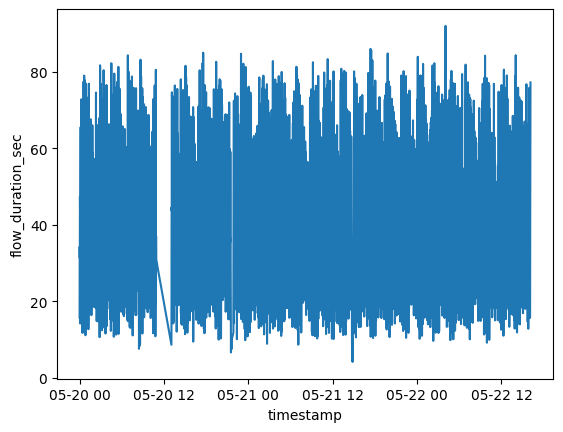

In [ ]:
sns.lineplot(x=flow.index, y=flow['flow_duration_sec'])

plt.show()

In [ ]:
flow[:1000]

,flow_duration_sec
timestamp,
2020-05-19 23:59:00,15.730159
2020-05-20 00:00:00,34.302752
2020-05-20 00:01:00,31.256410
2020-05-20 00:02:00,47.373626
2020-05-20 00:03:00,43.578947
...,...
2020-05-20 16:34:00,30.659091
2020-05-20 16:35:00,15.160000
2020-05-20 16:36:00,27.823529


In [ ]:
flow_filtered = flow.loc['2020-05-22 00:00:00':'2020-05-22 12:59:59']
display(flow_filtered)

,flow_duration_sec
timestamp,
2020-05-22 00:00:00,40.215054
2020-05-22 00:01:00,72.714286
2020-05-22 00:02:00,21.618182
2020-05-22 00:03:00,34.284722
2020-05-22 00:04:00,44.435115
...,...
2020-05-22 12:55:00,36.000000
2020-05-22 12:56:00,64.285714
2020-05-22 12:57:00,23.440000


In [ ]:
flow_filtered.iloc[61:80]

,flow_duration_sec
timestamp,
2020-05-22 01:01:00,68.607143
2020-05-22 01:02:00,17.821429
2020-05-22 01:03:00,19.228571
2020-05-22 01:04:00,26.779070
2020-05-22 01:05:00,37.614379
2020-05-22 01:06:00,65.803279
2020-05-22 01:07:00,15.800000
2020-05-22 01:08:00,20.923077
2020-05-22 01:09:00,39.553191


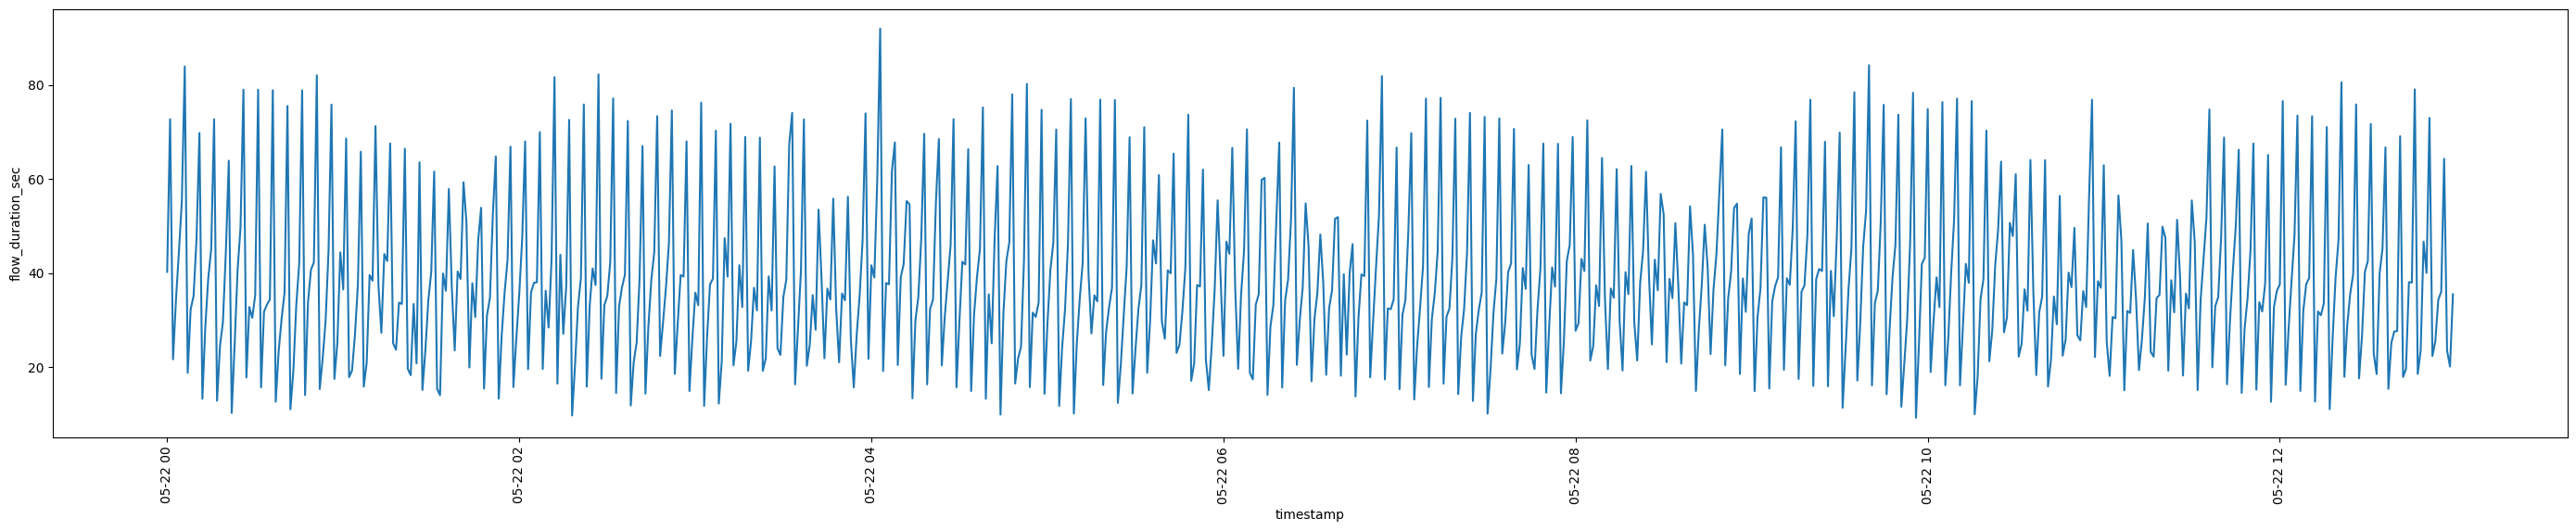

In [ ]:
plt.figure(figsize=(35, 6))
sns.lineplot(x=flow_filtered.index, y=flow_filtered['flow_duration_sec'])
plt.xticks(rotation=90)
plt.show()

In [ ]:
flow_filtered.shape

(780, 1)

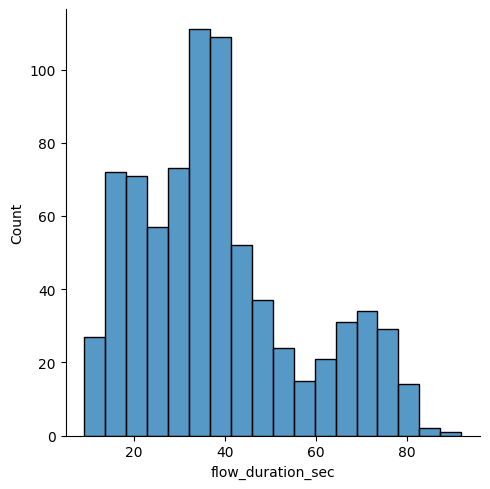

In [ ]:
sns.displot(x=flow_filtered['flow_duration_sec'])
plt.show()

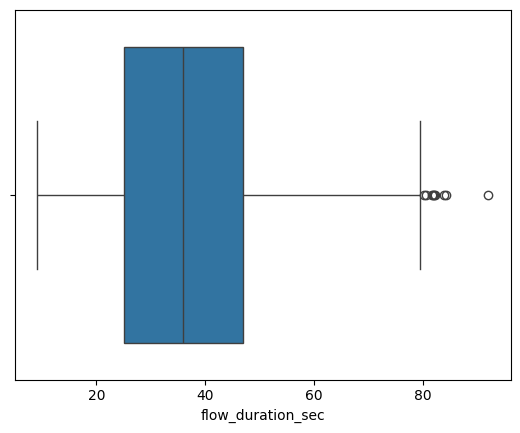

In [ ]:
sns.boxplot(x=flow_filtered['flow_duration_sec'])
plt.show()

In [ ]:
mean = flow_filtered['flow_duration_sec'].mean()
std = flow_filtered["flow_duration_sec"].std()
z_score = (flow_filtered['flow_duration_sec'] - mean) / std
flow_filtered['is_outlier'] = np.abs(z_score) > 3

print("Jumlah outlier terdeteksi:", flow_filtered['is_outlier'].sum())

Jumlah outlier terdeteksi: 0


/tmp/ipython-input-1286468152.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  flow_filtered['is_outlier'] = np.abs(z_score) > 3


In [ ]:
flow_filtered.head()

,flow_duration_sec,is_outlier
timestamp,,
2020-05-22 00:00:00,40.215054,False
2020-05-22 00:01:00,72.714286,False
2020-05-22 00:02:00,21.618182,False
2020-05-22 00:03:00,34.284722,False
2020-05-22 00:04:00,44.435115,False


In [ ]:
flow_filtered = flow_filtered.copy()
flow_filtered.drop('is_outlier', axis=1, inplace=True)
flow_filtered.head()

/tmp/ipython-input-2248481965.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  flow_filtered.drop('is_outlier', axis=1, inplace=True)


,flow_duration_sec
timestamp,
2020-05-22 00:00:00,40.215054
2020-05-22 00:01:00,72.714286
2020-05-22 00:02:00,21.618182
2020-05-22 00:03:00,34.284722
2020-05-22 00:04:00,44.435115


In [ ]:
Q1 = flow_filtered['flow_duration_sec'].quantile(0.25)
Q3 = flow_filtered['flow_duration_sec'].quantile(0.75)
IQR = Q3 - Q1

# Batas outlier
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1 =", Q1)
print("Q3 =", Q3)
print("IQR =", IQR)
print("Lower Bound =", lower_bound)
print("Upper Bound =", upper_bound)



Q1 = 25.038692136084777
Q3 = 46.96280991735537
IQR = 21.924117781270596
Lower Bound = -7.847484535821117
Upper Bound = 79.84898658926127


In [ ]:
flow_filtered['is_outlier'] = (flow_filtered['flow_duration_sec'] < lower_bound) | (flow_filtered['flow_duration_sec'] > upper_bound)

print("\nJumlah outlier terdeteksi:", flow_filtered['flow_duration_sec'].sum())




Jumlah outlier terdeteksi: 30175.452308709


/tmp/ipython-input-1820048488.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  flow_filtered['is_outlier'] = (flow_filtered['flow_duration_sec'] < lower_bound) | (flow_filtered['flow_duration_sec'] > upper_bound)


In [ ]:
flow_filtered.head()

,flow_duration_sec,is_outlier
timestamp,,
2020-05-22 00:00:00,40.215054,False
2020-05-22 00:01:00,72.714286,False
2020-05-22 00:02:00,21.618182,False
2020-05-22 00:03:00,34.284722,False
2020-05-22 00:04:00,44.435115,False


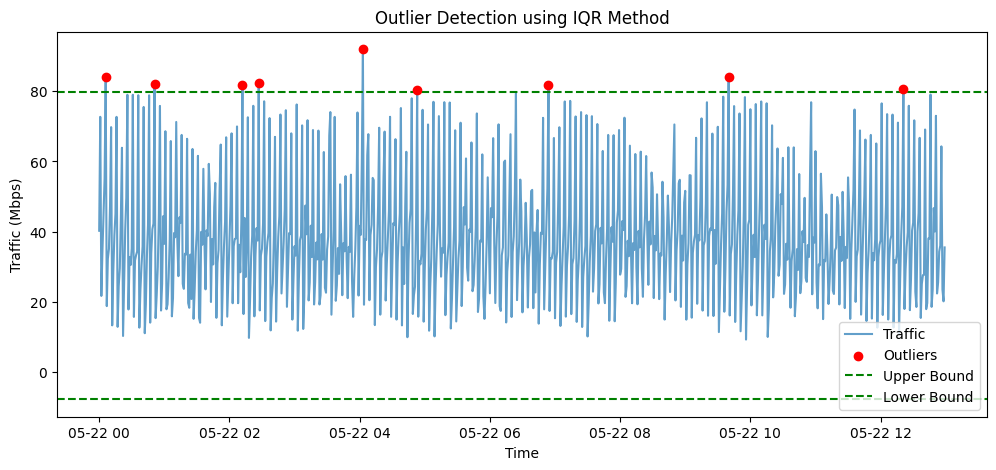

In [ ]:
# ===============================================================
# 4️⃣ Visualisasi hasil deteksi
# ===============================================================
plt.figure(figsize=(12,5))
plt.plot(flow_filtered.index, flow_filtered['flow_duration_sec'], label='Traffic', alpha=0.7)
plt.scatter(flow_filtered.index[flow_filtered['is_outlier']], flow_filtered['flow_duration_sec'][flow_filtered['is_outlier']],
            color='red', label='Outliers', zorder=5)
plt.axhline(upper_bound, color='green', linestyle='--', label='Upper Bound')
plt.axhline(lower_bound, color='green', linestyle='--', label='Lower Bound')
plt.title('Outlier Detection using IQR Method')
plt.xlabel('Time')
plt.ylabel('Traffic (Mbps)')
plt.legend()
plt.show()


In [ ]:
flow_filtered[flow_filtered['is_outlier']]

,flow_duration_sec,is_outlier
timestamp,,
2020-05-22 00:06:00,83.937500,True
2020-05-22 00:51:00,82.062500,True
2020-05-22 02:12:00,81.666667,True
2020-05-22 02:27:00,82.250000,True
2020-05-22 04:03:00,92.000000,True
2020-05-22 04:53:00,80.230769,True
2020-05-22 06:54:00,81.882353,True
2020-05-22 09:40:00,84.210526,True
2020-05-22 12:21:00,80.571429,True


In [ ]:
flow_filtered = flow_filtered.copy()
flow_filtered.drop(columns=["is_outlier", "rolling_mean", "rolling_std", "upper_bound", "lower_bound"], inplace=True)
flow_filtered.head()

,flow_duration_sec
timestamp,
2020-05-22 00:00:00,40.215054
2020-05-22 00:01:00,72.714286
2020-05-22 00:02:00,21.618182
2020-05-22 00:03:00,34.284722
2020-05-22 00:04:00,44.435115


In [ ]:
flow_filtered.head()

,flow_duration_sec
timestamp,
2020-05-22 00:00:00,40.215054
2020-05-22 00:01:00,72.714286
2020-05-22 00:02:00,21.618182
2020-05-22 00:03:00,34.284722
2020-05-22 00:04:00,44.435115


Iterasi ke-1: Ditemukan 0 outlier


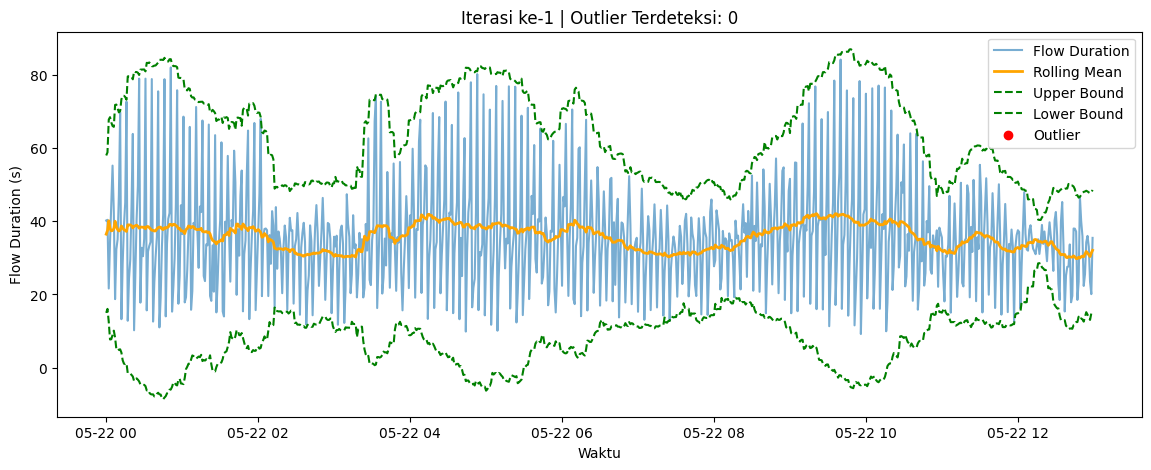

✅ Tidak ada outlier tersisa. Proses selesai.


In [ ]:
window_size = 20   # jendela 10 menit
threshold = 2      # batas 3x deviasi standar dari mean lokal

iteration = 0
while True:
    iteration += 1

    # Hapus kolom lama jika ada
    for col in ["is_outlier", "rolling_mean", "rolling_std", "upper_bound", "lower_bound"]:
        if col in flow_filtered.columns:
            flow_filtered.drop(columns=[col], inplace=True)

    # Rolling mean & std
    flow_filtered['rolling_mean'] = flow_filtered['flow_duration_sec'].rolling(
        window=window_size, center=True, min_periods=1).mean()
    flow_filtered['rolling_std'] = flow_filtered['flow_duration_sec'].rolling(
        window=window_size, center=True, min_periods=1).std()

    # Batas atas & bawah
    flow_filtered['upper_bound'] = flow_filtered['rolling_mean'] + threshold * flow_filtered['rolling_std']
    flow_filtered['lower_bound'] = flow_filtered['rolling_mean'] - threshold * flow_filtered['rolling_std']

    # Deteksi outlier
    flow_filtered['is_outlier'] = (
        (flow_filtered['flow_duration_sec'] > flow_filtered['upper_bound']) |
        (flow_filtered['flow_duration_sec'] < flow_filtered['lower_bound'])
    )

    outlier_count = flow_filtered['is_outlier'].sum()
    print(f"Iterasi ke-{iteration}: Ditemukan {outlier_count} outlier")

    # ==============================================================
    # 🎨 Visualisasi setiap iterasi
    # ==============================================================
    plt.figure(figsize=(14, 5))
    plt.plot(flow_filtered.index, flow_filtered['flow_duration_sec'], label='Flow Duration', alpha=0.6)
    plt.plot(flow_filtered.index, flow_filtered['rolling_mean'], label='Rolling Mean', color='orange', linewidth=2)
    plt.plot(flow_filtered.index, flow_filtered['upper_bound'], '--', color='green', label='Upper Bound')
    plt.plot(flow_filtered.index, flow_filtered['lower_bound'], '--', color='green', label='Lower Bound')
    plt.scatter(flow_filtered.index[flow_filtered['is_outlier']],
                flow_filtered['flow_duration_sec'][flow_filtered['is_outlier']],
                color='red', label='Outlier', zorder=5)
    plt.title(f'Iterasi ke-{iteration} | Outlier Terdeteksi: {outlier_count}')
    plt.xlabel('Waktu')
    plt.ylabel('Flow Duration (s)')
    plt.legend()
    plt.show()

    # ==============================================================
    # Ganti outlier dengan rolling mean
    # ==============================================================
    flow_filtered.loc[flow_filtered['is_outlier'], 'flow_duration_sec'] = flow_filtered['rolling_mean']

    # ==============================================================
    # Berhenti jika tidak ada outlier lagi
    # ==============================================================
    if outlier_count == 0:
        print("✅ Tidak ada outlier tersisa. Proses selesai.")
        break

In [ ]:
flow_filtered = flow_filtered.copy()
flow_filtered.drop(columns=["is_outlier", "rolling_mean", "rolling_std", "upper_bound", "lower_bound"], inplace=True)
flow_filtered.head()

,flow_duration_sec
timestamp,
2020-05-22 00:00:00,40.215054
2020-05-22 00:01:00,40.387516
2020-05-22 00:02:00,21.618182
2020-05-22 00:03:00,34.284722
2020-05-22 00:04:00,44.435115


In [ ]:
from statsmodels.tsa.stattools import adfuller

# Ambil kolom data bersih
series = flow_filtered['flow_duration_sec'].dropna()

# Lakukan uji ADF
result = adfuller(series)

# Tampilkan hasil
print('ADF Statistic:', result[0])
print('p-value:', result[1])
for key, value in result[4].items():
    print(f'Critical Value ({key}): {value}')

# Interpretasi
if result[1] < 0.05:
    print("✅ Data stasioner (tolak H0)")
else:
    print("⚠️ Data non-stasioner (gagal tolak H0, perlu transformasi)")


ADF Statistic: -2.627720141625386
p-value: 0.08740233893399302
Critical Value (1%): -3.4389949984547465
Critical Value (5%): -2.865355478124818
Critical Value (10%): -2.568801753520772
⚠️ Data non-stasioner (gagal tolak H0, perlu transformasi)


In [ ]:
# --- Split train/test ---
train_size = int(len(flow_filtered) * 0.75)
train = flow_filtered.iloc[:train_size]
test = flow_filtered.iloc[train_size:]


In [ ]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# --- Scaling ---
scaler = MinMaxScaler()
scaler.fit(train[['flow_duration_sec']])
train_scaled = scaler.transform(train[['flow_duration_sec']])
test_scaled = scaler.transform(test[['flow_duration_sec']])

In [1]:
# Gabungkan hasil scaling ke dataframe
flow_filtered.loc[train.index, 'scaled'] = train_scaled
flow_filtered.loc[test.index, 'scaled'] = test_scaled

NameError: name 'train_scaled' is not defined

In [ ]:
# --- Sequence creation ---
def create_sequences(data, window):
    X, y = [], []
    for i in range(window, len(data)):
        X.append(data[i-window:i])
        y.append(data[i])
    return np.array(X), np.array(y)

window_size = 120  # gunakan 1 jam terakhir untuk prediksi menit berikutnya
values = flow_filtered['scaled'].values
X, y = create_sequences(values, window_size)


In [ ]:
train_size = int(len(X) * 0.75)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

In [ ]:
pip install tensorflow

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import numpy as np

model = Sequential([
    LSTM(128, activation='tanh', return_sequences=True, input_shape=(window_size, 1)),
    Dropout(0.2),
    LSTM(64, activation='tanh'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1)
])
model.compile(optimizer='adam', loss='mse')
model.summary()

# Add Early Stopping and ReduceLROnPlateau callbacks
es = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=0.0001)

Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_45 (LSTM)                  │ (None, 120, 128)       │        66,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_40 (Dropout)            │ (None, 120, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_46 (LSTM)                  │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_41 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 118,081 (461.25 KB)

 Trainable params: 118,081 (461.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(X_train, y_train, epochs=100, batch_size=32,
                    validation_split=0.2, verbose=1, callbacks=[es, reduce_lr])

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 312ms/step - loss: 0.0172 - val_loss: 0.0111
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 220ms/step - loss: 0.0168 - val_loss: 0.0169
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 371ms/step - loss: 0.0120 - val_loss: 0.0065
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 225ms/step - loss: 0.0146 - val_loss: 0.0100
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 217ms/step - loss: 0.0126 - val_loss: 0.0083
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 218ms/step - loss: 0.0119 - val_loss: 0.0091
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 330ms/step - loss: 0.0129 - val_loss: 0.0070
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 270ms/step - loss: 0.0142 - val_loss: 0.0091
Epoch 9/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 230ms/step - loss: 0.0126 - val_loss: 0.0060
Epoch 10/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 232ms/step - loss: 0.0122 - val_loss: 0.0112
Epoch 11/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 283ms/step - loss: 0.0132 - val_loss: 0.0057
Epoch 12/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 4

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step
MAE  : 5.310
RMSE : 6.578


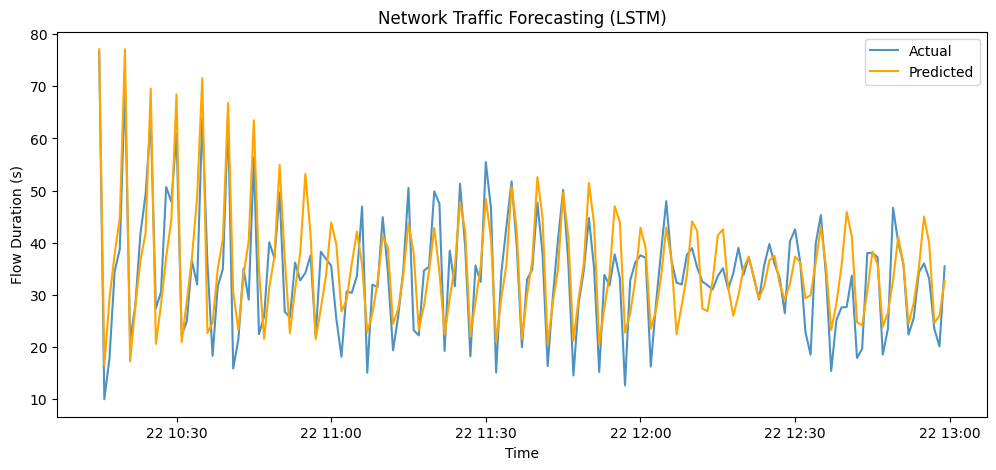

In [ ]:
# --- Evaluasi ---
y_pred = model.predict(X_test)
y_pred_rescaled = scaler.inverse_transform(y_pred)
y_test_rescaled = scaler.inverse_transform(y_test.reshape(-1,1))

from sklearn.metrics import mean_absolute_error, mean_squared_error
mae = mean_absolute_error(y_test_rescaled, y_pred_rescaled)
rmse = np.sqrt(mean_squared_error(y_test_rescaled, y_pred_rescaled))
print(f"MAE  : {mae:.3f}")
print(f"RMSE : {rmse:.3f}")

# Visualisasi
plt.figure(figsize=(12,5))
plt.plot(flow_filtered.index[-len(y_test):], y_test_rescaled, label='Actual', alpha=0.8)
plt.plot(flow_filtered.index[-len(y_pred):], y_pred_rescaled, label='Predicted', color='orange')
plt.title('Network Traffic Forecasting (LSTM)')
plt.xlabel('Time')
plt.ylabel('Flow Duration (s)')
plt.legend()
plt.show()

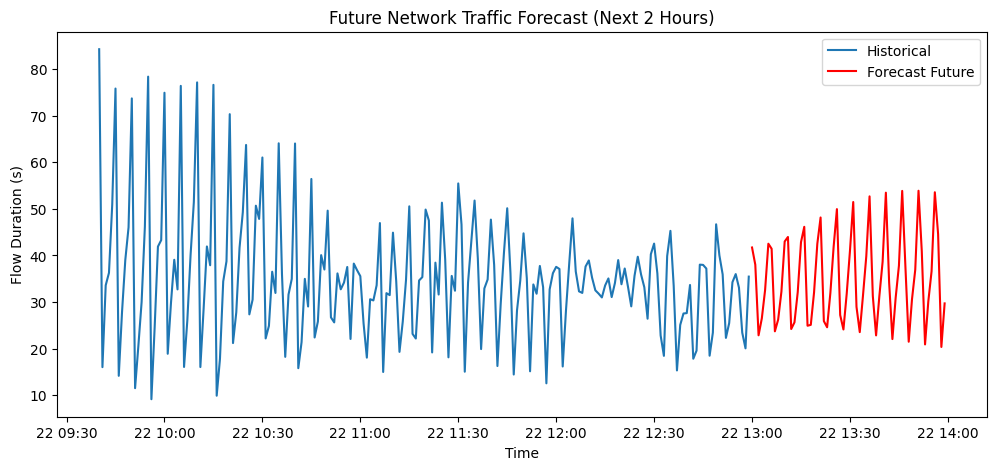

In [ ]:
future_steps = 60
last_sequence = values[-window_size:]
predictions = []

current_seq = last_sequence.copy()

for _ in range(future_steps):
    pred = model.predict(current_seq.reshape(1, window_size, 1), verbose=0)[0][0]
    predictions.append(pred)
    current_seq = np.append(current_seq[1:], pred)  # geser window

# Kembalikan ke skala asli
pred_future = scaler.inverse_transform(np.array(predictions).reshape(-1,1))

# Plot hasil
future_index = pd.date_range(flow_filtered.index[-1], periods=future_steps+1, freq='min')[1:]
plt.figure(figsize=(12,5))
plt.plot(flow_filtered.index[-200:], flow_filtered['flow_duration_sec'].iloc[-200:], label='Historical')
plt.plot(future_index, pred_future, label='Forecast Future', color='red')
plt.title('Future Network Traffic Forecast (Next 2 Hours)')
plt.xlabel('Time')
plt.ylabel('Flow Duration (s)')
plt.legend()
plt.show()